# Forecast horizon

Same holdout as the other notebooks. The question is how much MAE costs when the prediction has to be made earlier.

Five information sets, from the one that can be issued on any future day to the one that exists only after the previous hour has finished:

| Set | When it can be issued |
| --- | --- |
| Hour-of-day mean | Any future day. It is the training average for that local hour. |
| Yesterday, same hour | 24 hours ahead. Persistence. |
| Day-ahead features | About 24 hours ahead. Clock, last week of carbon, yesterday's weather, CAISO demand forecast. |
| Same-hour weather and demand | During the hour. Replaces yesterday's weather with the observation, and adds actual demand. |
| Previous hour of carbon | 1 hour ahead. The day-ahead set plus carbon from the last hour. |

Ridge retunes its penalty on each learned set. The tree uses the shared absolute-error settings rather than a new depth search, so this notebook is about the information, not a second hyperparameter hunt. Fuel generation stays out of every set.

In [1]:
%matplotlib inline

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titlesize"] = 12

from sklearn.linear_model import Ridge

from src.modeling import (
    DAY_AHEAD_CATEGORICAL,
    DAY_AHEAD_NUMERIC,
    DEMAND_FORECAST,
    HISTORY,
    HOUR_DOW,
    OBSERVED_NOW,
    PREVIOUS_HOUR,
    SEASON,
    cross_validated_mae,
    feature_matrix,
    linear_pipeline,
    make_tree,
    search_time_series,
)

LEARNED = {
    "day-ahead features": (DAY_AHEAD_CATEGORICAL, DAY_AHEAD_NUMERIC, "about 24 hours ahead"),
    "same-hour weather and demand": (
        HOUR_DOW,
        SEASON + HISTORY + OBSERVED_NOW + DEMAND_FORECAST,
        "during the hour",
    ),
    "previous hour of carbon": (
        HOUR_DOW,
        DAY_AHEAD_NUMERIC + PREVIOUS_HOUR,
        "1 hour ahead",
    ),
}

from src.carbon_data import load_model_frame
from src.modeling import TARGET, hour_climatology, result_row, score_predictions, train_test_split

frame = load_model_frame()
train, test = train_test_split(frame)
assert train.index.max() < test.index.min()
baseline = hour_climatology(train, test)
baseline_mae = score_predictions(test[TARGET], baseline)["mae"]
print(f"{len(frame)} hours, {frame.index.min():%Y-%m-%d} to {frame.index.max():%Y-%m-%d} UTC")
print(
    f"train {len(train)} hours through {train.index.max():%Y-%m-%d %H} UTC; "
    f"test {len(test)} hours from {test.index.min():%Y-%m-%d %H} UTC"
)
print(f"hour-of-day baseline MAE on the test block: {baseline_mae:.2f} g/kWh")


6793 hours, 2026-01-08 to 2026-10-18 UTC
train 6120 hours through 2026-09-20 22 UTC; test 673 hours from 2026-09-20 23 UTC
hour-of-day baseline MAE on the test block: 70.62 g/kWh


## Fit

The hour-of-day mean and yesterday's carbon are baselines with nothing to tune. For each learned set, ridge picks `alpha` on forward folds, and one tree is scored the same way with the depth and learning rate held fixed.

In [2]:
rows = [
    result_row("hour-of-day mean", test[TARGET], baseline, float("nan"), baseline_mae)
    | {"known": "any future day", "family": "baseline"},
    result_row("yesterday, same hour", test[TARGET], test["carbon_lag_24"], float("nan"), baseline_mae)
    | {"known": "24 hours ahead", "family": "baseline"},
]
y_train = train[TARGET]
y_test = test[TARGET]

for label, (categorical, numeric, known) in LEARNED.items():
    x_train = feature_matrix(train, categorical, numeric)
    x_test = feature_matrix(test, categorical, numeric)
    ridge = search_time_series(
        linear_pipeline(Ridge(), categorical, numeric),
        {"model__alpha": [0.01, 0.1, 1.0, 10.0, 100.0]},
        x_train,
        y_train,
    )
    detail = ", ".join(f"{key.split('model__')[-1]}={value:g}" for key, value in ridge.best_params_.items())
    rows.append(
        result_row(f"ridge / {label}", y_test, ridge.predict(x_test), -ridge.best_score_, baseline_mae)
        | {"known": known, "family": "ridge", "detail": detail}
    )
    tree = make_tree(loss="absolute_error")
    tree.set_params(categorical_features=list(range(len(categorical))))
    cv_mae = cross_validated_mae(tree, x_train, y_train)
    tree.fit(x_train, y_train)
    rows.append(
        result_row(f"tree / {label}", y_test, tree.predict(x_test), cv_mae, baseline_mae)
        | {"known": known, "family": "tree", "detail": "shared absolute-error tree"}
    )

order = [
    "hour-of-day mean",
    "yesterday, same hour",
    "ridge / day-ahead features",
    "tree / day-ahead features",
    "ridge / same-hour weather and demand",
    "tree / same-hour weather and demand",
    "ridge / previous hour of carbon",
    "tree / previous hour of carbon",
]
table = pd.DataFrame(rows).set_index("model").loc[order].reset_index()
table.round(3)


/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in ma

/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in ma

/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in ma

,model,mae,rmse,cv_mae,skill_vs_hour,known,family,detail
0,hour-of-day mean,70.622,83.744,NaN,0.000,any future day,baseline,NaN
1,"yesterday, same hour",27.181,33.992,NaN,0.615,24 hours ahead,baseline,NaN
2,ridge / day-ahead features,24.679,31.475,23.903,0.651,about 24 hours ahead,ridge,alpha=100
3,tree / day-ahead features,30.787,38.495,27.362,0.564,about 24 hours ahead,tree,shared absolute-error tree
4,ridge / same-hour weather and demand,23.363,29.700,23.978,0.669,during the hour,ridge,alpha=100
5,tree / same-hour weather and demand,30.263,37.266,29.055,0.571,during the hour,tree,shared absolute-error tree
6,ridge / previous hour of carbon,10.155,14.665,9.725,0.856,1 hour ahead,ridge,alpha=10
7,tree / previous hour of carbon,8.770,12.676,8.827,0.876,1 hour ahead,tree,shared absolute-error tree


## What the extra wait buys

Read the table down the page: each block is available later than the one above it. The day-ahead rows are the ones that can still be issued the day before. The previous-hour rows are accurate because carbon moves smoothly from one hour to the next, and they are only available if the decision can wait.

Ridge test MAE is 24.68 g/kWh a day ahead, 23.36 with same-hour weather and demand, and 10.15 once the previous hour of carbon is known. The tree beats ridge only on that last horizon, at 8.77.


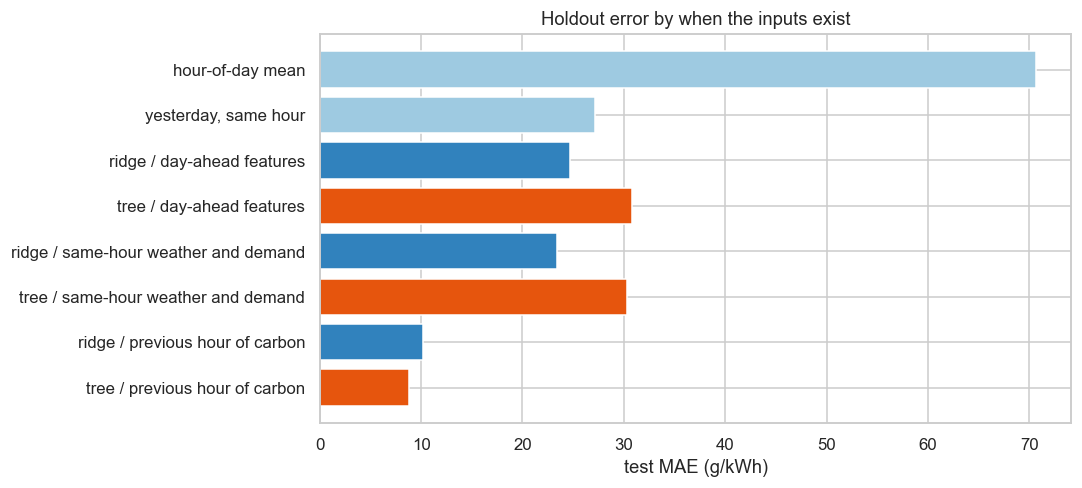

In [3]:
fig, ax = plt.subplots(figsize=(10, 4.6))
colors = {"baseline": "#9ecae1", "ridge": "#3182bd", "tree": "#e6550d"}
ax.barh(table["model"], table["mae"], color=[colors[family] for family in table["family"]])
ax.set_xlabel("test MAE (g/kWh)")
ax.invert_yaxis()
ax.set_title("Holdout error by when the inputs exist")
fig.tight_layout()

day_ahead = table.loc[table["model"] == "ridge / day-ahead features"].iloc[0]
same_hour = table.loc[table["model"] == "ridge / same-hour weather and demand"].iloc[0]
next_hour = table.loc[table["model"] == "ridge / previous hour of carbon"].iloc[0]
next_tree = table.loc[table["model"] == "tree / previous hour of carbon"].iloc[0]
print(
    f"Ridge test MAE is {day_ahead['mae']:.2f} g/kWh a day ahead, "
    f"{same_hour['mae']:.2f} with same-hour weather and demand, "
    f"and {next_hour['mae']:.2f} once the previous hour of carbon is known. "
    f"The tree beats ridge only on that last horizon, at {next_tree['mae']:.2f}."
)
